<a href="https://colab.research.google.com/github/Lapindodu/EMSE_labs/blob/main/LR_2_task_3_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%%writefile utilities.py
import numpy as np
import matplotlib.pyplot as plt

def visualize_classifier(classifier, X, y):
    min_x, max_x = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
    min_y, max_y = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0
    mesh_step_size = 0.01

    x_vals, y_vals = np.meshgrid(np.arange(min_x, max_x, mesh_step_size),
                                 np.arange(min_y, max_y, mesh_step_size))

    output = classifier.predict(np.c_[x_vals.ravel(), y_vals.ravel()])
    output = output.reshape(x_vals.shape)

    plt.figure()
    plt.pcolormesh(x_vals, y_vals, output, cmap=plt.cm.gray, shading='auto')
    plt.scatter(X[:, 0], X[:, 1], c=y, s=75, edgecolors='black', linewidth=1, cmap=plt.cm.Paired)

    plt.xlim(x_vals.min(), x_vals.max())
    plt.ylim(y_vals.min(), y_vals.max())
    plt.xticks((np.arange(int(X[:, 0].min() - 1), int(X[:, 0].max() + 2), 1.0)))
    plt.yticks((np.arange(int(X[:, 1].min() - 1), int(X[:, 1].max() + 2), 1.0)))
    plt.show()

Writing utilities.py


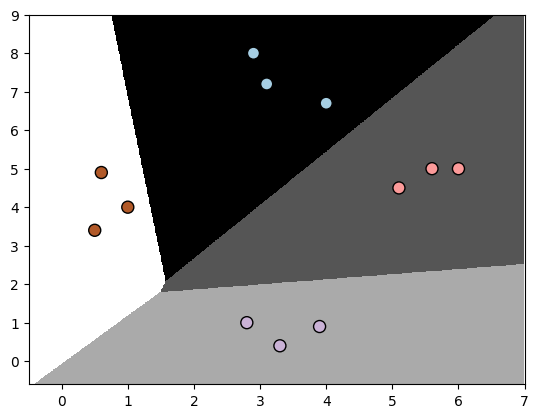

In [5]:
# ЗАВДАННЯ 2.3
import numpy as np
from sklearn import linear_model
import matplotlib.pyplot as plt
from utilities import visualize_classifier

X = np.array([
    [3.1, 7.2], [4, 6.7], [2.9, 8],
    [5.1, 4.5], [6, 5], [5.6, 5],
    [3.3, 0.4], [3.9, 0.9], [2.8, 1],
    [0.5, 3.4], [1, 4], [0.6, 4.9]
])
y = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2, 3, 3, 3])

classifier = linear_model.LogisticRegression(solver='liblinear', C=1)
classifier.fit(X, y)

visualize_classifier(classifier, X, y)

Accuracy of Naive Bayes classifier = 95.75 %


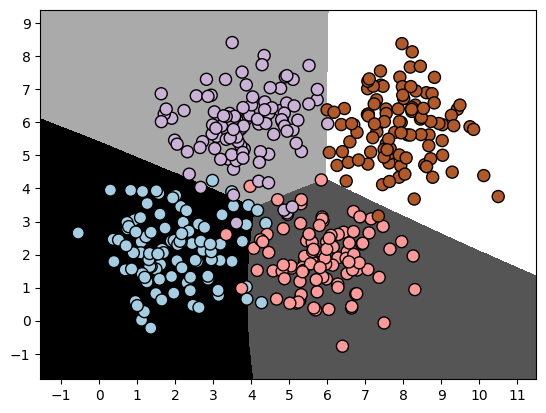

Accuracy of the new classifier = 98.75 %


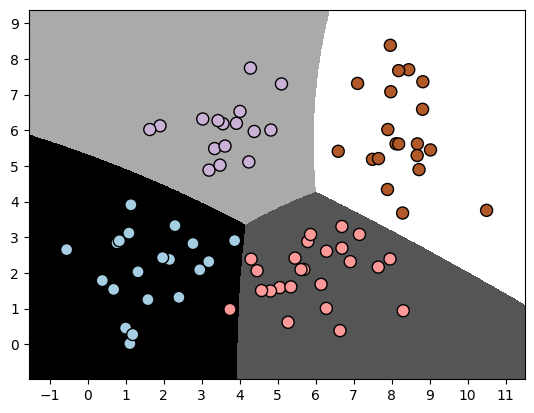

Accuracy: 95.25%
Precision: 95.4%
Recall: 95.25%
F1: 95.27%


In [7]:
# ЗАВДАННЯ 2.4
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split, cross_val_score
from utilities import visualize_classifier

input_file = 'data_multivar_nb.txt'
data = np.loadtxt(input_file, delimiter=',')
X, y = data[:, :-1], data[:, -1]

classifier = GaussianNB()
classifier.fit(X, y)

y_pred = classifier.predict(X)
accuracy = 100.0 * (y == y_pred).sum() / X.shape[0]
print("Accuracy of Naive Bayes classifier =", round(accuracy, 2), "%")

visualize_classifier(classifier, X, y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=3)
classifier_new = GaussianNB()
classifier_new.fit(X_train, y_train)
y_test_pred = classifier_new.predict(X_test)

accuracy_new = 100.0 * (y_test == y_test_pred).sum() / X_test.shape[0]
print("Accuracy of the new classifier =", round(accuracy_new, 2), "%")

visualize_classifier(classifier_new, X_test, y_test)

num_folds = 3

accuracy_values = cross_val_score(classifier, X, y, scoring='accuracy', cv=num_folds)
print("Accuracy: " + str(round(100 * accuracy_values.mean(), 2)) + "%")

precision_values = cross_val_score(classifier, X, y, scoring='precision_weighted', cv=num_folds)
print("Precision: " + str(round(100 * precision_values.mean(), 2)) + "%")

recall_values = cross_val_score(classifier, X, y, scoring='recall_weighted', cv=num_folds)
print("Recall: " + str(round(100 * recall_values.mean(), 2)) + "%")

f1_values = cross_val_score(classifier, X, y, scoring='f1_weighted', cv=num_folds)
print("F1: " + str(round(100 * f1_values.mean(), 2)) + "%")

SCORES WITH THRESHOLD = 0.5 
Accuracy RF: 0.844
Recall RF: 0.844
Precision RF: 0.843
F1 RF: 0.844

 SCORES WITH THRESHOLD = 0.25 
Accuracy RF: 0.695
Recall RF: 0.987
Precision RF: 0.622
F1 RF: 0.763


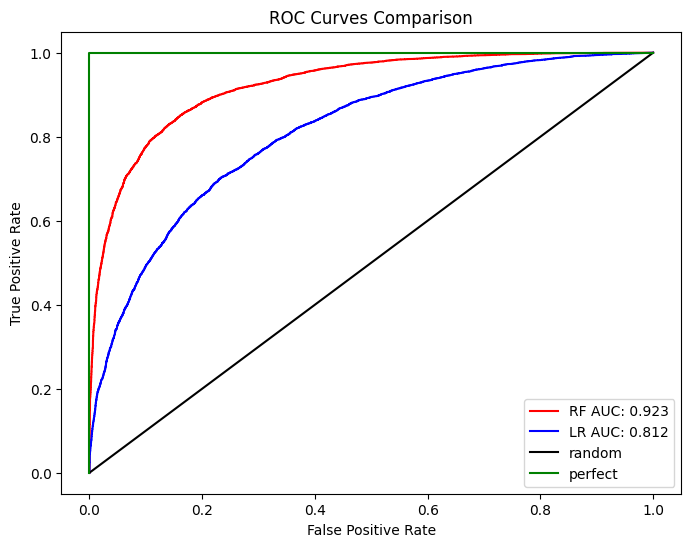

In [11]:
# ЗАВДАННЯ 2.5
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, f1_score, roc_curve, roc_auc_score

np.random.seed(42)
n_samples = 15758
actual_label = np.random.randint(0, 2, size=n_samples)
model_RF = np.clip(actual_label * 0.4 + np.random.normal(0.3, 0.2, size=n_samples), 0, 1)
model_LR = np.clip(actual_label * 0.25 + np.random.normal(0.35, 0.2, size=n_samples), 0, 1)

df = pd.DataFrame({'actual_label': actual_label, 'model_RF': model_RF, 'model_LR': model_LR})

df['predicted_RF'] = (df.model_RF >= 0.5).astype('int')
df['predicted_LR'] = (df.model_LR >= 0.5).astype('int')

# 2. Власні функції розрахунку елементів Confusion Matrix (Зайцева Катерина)
def find_TP(y_true, y_pred):
    return sum((y_true == 1) & (y_pred == 1))

def find_FN(y_true, y_pred):
    return sum((y_true == 1) & (y_pred == 0))

def find_FP(y_true, y_pred):
    return sum((y_true == 0) & (y_pred == 1))

def find_TN(y_true, y_pred):
    return sum((y_true == 0) & (y_pred == 0))

def find_conf_matrix_values(y_true, y_pred):
    return find_TP(y_true, y_pred), find_FN(y_true, y_pred), find_FP(y_true, y_pred), find_TN(y_true, y_pred)

def zaitseva_confusion_matrix(y_true, y_pred):
    TP, FN, FP, TN = find_conf_matrix_values(y_true, y_pred)
    return np.array([[TN, FP], [FN, TP]])

assert np.array_equal(zaitseva_confusion_matrix(df.actual_label.values, df.predicted_RF.values),
                     confusion_matrix(df.actual_label.values, df.predicted_RF.values))

def zaitseva_accuracy_score(y_true, y_pred):
    TP, FN, FP, TN = find_conf_matrix_values(y_true, y_pred)
    return (TP + TN) / (TP + TN + FP + FN)

def zaitseva_recall_score(y_true, y_pred):
    TP, FN, FP, TN = find_conf_matrix_values(y_true, y_pred)
    return TP / (TP + FN)

def zaitseva_precision_score(y_true, y_pred):
    TP, FN, FP, TN = find_conf_matrix_values(y_true, y_pred)
    return TP / (TP + FP)

def zaitseva_f1_score(y_true, y_pred):
    recall = zaitseva_recall_score(y_true, y_pred)
    precision = zaitseva_precision_score(y_true, y_pred)
    return 2 * (precision * recall) / (precision + recall)

print('SCORES WITH THRESHOLD = 0.5 ')
print('Accuracy RF: %.3f' % zaitseva_accuracy_score(df.actual_label.values, df.predicted_RF.values))
print('Recall RF: %.3f' % zaitseva_recall_score(df.actual_label.values, df.predicted_RF.values))
print('Precision RF: %.3f' % zaitseva_precision_score(df.actual_label.values, df.predicted_RF.values))
print('F1 RF: %.3f' % zaitseva_f1_score(df.actual_label.values, df.predicted_RF.values))

print('\n SCORES WITH THRESHOLD = 0.25 ')
rf_025 = (df.model_RF >= 0.25).astype('int').values
print('Accuracy RF: %.3f' % zaitseva_accuracy_score(df.actual_label.values, rf_025))
print('Recall RF: %.3f' % zaitseva_recall_score(df.actual_label.values, rf_025))
print('Precision RF: %.3f' % zaitseva_precision_score(df.actual_label.values, rf_025))
print('F1 RF: %.3f' % zaitseva_f1_score(df.actual_label.values, rf_025))

fpr_RF, tpr_RF, thresholds_RF = roc_curve(df.actual_label.values, df.model_RF.values)
fpr_LR, tpr_LR, thresholds_LR = roc_curve(df.actual_label.values, df.model_LR.values)

auc_RF = roc_auc_score(df.actual_label.values, df.model_RF.values)
auc_LR = roc_auc_score(df.actual_label.values, df.model_LR.values)

plt.figure(figsize=(8, 6))
plt.plot(fpr_RF, tpr_RF, 'r-', label='RF AUC: %.3f' % auc_RF)
plt.plot(fpr_LR, tpr_LR, 'b-', label='LR AUC: %.3f' % auc_LR)
plt.plot([0, 1], [0, 1], 'k-', label='random')
plt.plot([0, 0, 1, 1], [0, 1, 1, 1], 'g-', label='perfect')
plt.legend()
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison')
plt.show()

In [12]:
# ЗАВДАННЯ 2.6
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

input_file = 'data_multivar_nb.txt'
data = np.loadtxt(input_file, delimiter=',')
X, y = data[:, :-1], data[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)

svm_model = SVC(kernel='rbf', C=1.0)
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)

metrics = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Naive Bayes': [
        accuracy_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_nb, average='weighted'),
        recall_score(y_test, y_pred_nb, average='weighted'),
        f1_score(y_test, y_pred_nb, average='weighted')
    ],
    'SVM (RBF Kernel)': [
        accuracy_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_svm, average='weighted'),
        recall_score(y_test, y_pred_svm, average='weighted'),
        f1_score(y_test, y_pred_svm, average='weighted')
    ]
}

df_results = pd.DataFrame(metrics)
print("ПОРІВНЯННЯ ПОКАЗНИКІВ ЯКОСТІ КЛАСИФІКАЦІЇ ")
print(df_results.to_string(index=False))

ПОРІВНЯННЯ ПОКАЗНИКІВ ЯКОСТІ КЛАСИФІКАЦІЇ 
   Metric  Naive Bayes  SVM (RBF Kernel)
 Accuracy     0.937500          0.937500
Precision     0.938765          0.938765
   Recall     0.937500          0.937500
 F1-Score     0.937255          0.937255
